# 03 - Text Baseline Models

## Objective

In this notebook, we establish the first baseline models for the Rakuten product-classification task:

1. **Largest-class baseline:** A minimal floor score predicting the most common category.
2. **TF-IDF + Linear SVM:** A fast, standard text classifier.
3. **Visual interpretability:** Inspecting what product text and images look like for key categories.
4. **Cleaning comparison:** An experiment testing whether text cleaning actually improves the baseline.
5. **Error analysis:** Inspecting where the classifier succeeds, where it gets confused, and why.


## 1. Load the Prepared Text

We load the preprocessed dataset with the shared 80/20 train/validation split. The `text_combined` column contains product title and description merged together.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.svm import LinearSVC
from src.data_utils import load_merged_data, get_image_path

processed_path = Path("../data/processed/text_train_processed.csv")
data = pd.read_csv(processed_path)

model_train = data[data["split"] == "train"].copy()
model_validation = data[data["split"] == "validation"].copy()

print(f"Training products:   {len(model_train):,}")
print(f"Validation products: {len(model_validation):,}")


Training products:   67,932
Validation products: 16,984


### Analysis

- We have **67,932 training products (80%)** and **16,984 validation products (20%)**.
- The split is stratified by product category, so all 27 categories are represented in both sets in the exact same proportions.
- Keeping this split fixed ensures fair comparison across all future models (text, image, and multimodal).


## 2. Largest-Class Baseline

This baseline predicts the most common training category for every product. It ignores the text completely and sets the absolute minimum score that any useful model must beat.


In [2]:
y_train = model_train["prdtypecode"]
y_validation = model_validation["prdtypecode"]

largest_class = y_train.value_counts().idxmax()
majority_predictions = np.full(len(model_validation), largest_class)

majority_weighted_f1 = f1_score(y_validation, majority_predictions, average="weighted")
majority_macro_f1 = f1_score(y_validation, majority_predictions, average="macro")

print(f"Largest class: {largest_class}")
print(f"Weighted F1:   {majority_weighted_f1:.4f}")
print(f"Macro F1:      {majority_macro_f1:.4f}")


Largest class: 2583
Weighted F1:   0.0258
Macro F1:      0.0080


### Analysis

- Always guessing the most frequent category (class 2583) yields a **Weighted F1 of 0.0258** and a **Macro F1 of 0.0080**.
- Because the catalog has 27 categories, naive guessing gets almost everything wrong.
- This sets our absolute floor: any trained machine learning model must beat this score easily.


## 3. Convert Text into TF-IDF Features

We convert the text into numerical TF-IDF features using word unigrams and bigrams up to 50,000 features. The vocabulary is learned only from the training set to avoid data leakage.


In [3]:
vectorizer = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),
    min_df=2,
)

X_train = vectorizer.fit_transform(model_train["text_combined"])
X_validation = vectorizer.transform(model_validation["text_combined"])

print(f"Training matrix:   {X_train.shape}")
print(f"Validation matrix: {X_validation.shape}")


Training matrix:   (67932, 50000)
Validation matrix: (16984, 50000)


### Analysis

- Each product is now represented as a sparse vector across **50,000 word and 2-word n-gram features**.
- TF-IDF gives higher weight to terms specific to certain products (like *playstation* or *sommier*) and downweights common French words (like *pour* or *avec*).
- Fitting only on the training set protects us from data leakage.


## 4. Train the First Text Classifier (Linear SVM)

Linear SVM is a standard, fast baseline for high-dimensional TF-IDF text features. It trains in seconds and provides a strong reference score for later models.


In [4]:
text_model = LinearSVC(random_state=42)
text_model.fit(X_train, y_train)
text_predictions = text_model.predict(X_validation)

text_weighted_f1 = f1_score(y_validation, text_predictions, average="weighted")
text_macro_f1 = f1_score(y_validation, text_predictions, average="macro")

results = pd.DataFrame({
    "model": ["Largest-class baseline", "TF-IDF + Linear SVM"],
    "weighted_f1": [majority_weighted_f1, text_weighted_f1],
    "macro_f1": [majority_macro_f1, text_macro_f1],
})
results.round(4)


,model,weighted_f1,macro_f1
0,Largest-class baseline,0.0258,0.0080
1,TF-IDF + Linear SVM,0.8274,0.8156


### Analysis

- The Linear SVM achieves a **Weighted F1 of 0.8274**, comfortably beating the official Rakuten text benchmark of **0.8113**.
- **Macro F1 is 0.8156**, very close to the weighted score, showing that the model performs well across both large and small categories without neglecting minority classes.
- The model trains in under 20 seconds, making it a very strong and fast reference point.


## 5. How the Classifier Makes Decisions & What Categories Look Like

To see what the model is actually learning, we take a correctly predicted product and inspect its **catalog image**, its **top keywords**, and the model's **decision scores**.

We also look at sample product images from common categories to see what these numeric category codes actually represent in reality.


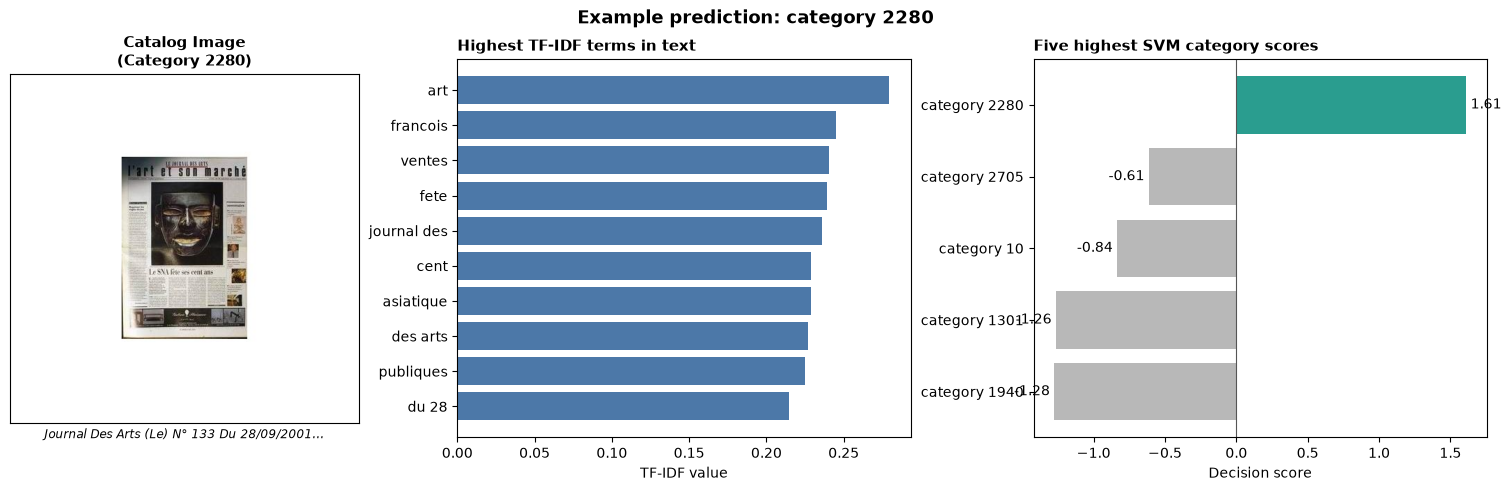

In [5]:
# Pick a correctly classified product with at least 10 words
word_counts = (X_validation > 0).sum(axis=1).A1
candidates = np.where((text_predictions == y_validation.to_numpy()) & (word_counts >= 10))[0]
idx = candidates[0]

val_row = model_validation.iloc[idx]
raw_row = load_merged_data().loc[val_row["row_id"]]
img_path = get_image_path(raw_row["imageid"], raw_row["productid"])
product_img = Image.open(img_path)

sample_vector = X_validation[idx]
predicted_class = text_predictions[idx]
feature_names = vectorizer.get_feature_names_out()

# Top 10 words by TF-IDF value
sample_words = pd.Series(sample_vector.toarray().ravel(), index=feature_names)
top_words = sample_words[sample_words > 0].nlargest(10).sort_values()

# Top 5 category scores from the SVM
class_scores = text_model.decision_function(sample_vector).ravel()
top_classes = pd.Series(class_scores, index=text_model.classes_).nlargest(5).sort_values()

# 3-panel figure: [Product Image] | [Top Keywords] | [Top Category Decision Scores]
fig = plt.figure(figsize=(15, 4.8), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.3, 1.3])

ax_img = fig.add_subplot(gs[0])
ax_words = fig.add_subplot(gs[1])
ax_scores = fig.add_subplot(gs[2])

# 1. Product Image
ax_img.imshow(product_img)
ax_img.set_xticks([])
ax_img.set_yticks([])
ax_img.set_title(f"Catalog Image\n(Category {val_row['prdtypecode']})", fontsize=11, fontweight="bold")
ax_img.set_xlabel(f"{raw_row['designation'][:42]}...", fontsize=8.5, style="italic")

# 2. Top TF-IDF Terms
ax_words.barh(top_words.index, top_words.values, color="#4c78a8")
ax_words.set_title("Highest TF-IDF terms in text", loc="left", fontsize=11, fontweight="bold")
ax_words.set_xlabel("TF-IDF value")

# 3. Category Decision Scores
score_colors = ["#b8b8b8"] * 4 + ["#2a9d8f"]
bars = ax_scores.barh([f"category {c}" for c in top_classes.index], top_classes.values, color=score_colors)
ax_scores.axvline(0, color="#555555", linewidth=0.8)
ax_scores.set_title("Five highest SVM category scores", loc="left", fontsize=11, fontweight="bold")
ax_scores.set_xlabel("Decision score")
ax_scores.bar_label(bars, fmt="%.2f", padding=3)

fig.suptitle(f"Example prediction: category {predicted_class}", fontsize=13, fontweight="bold")
plt.show()


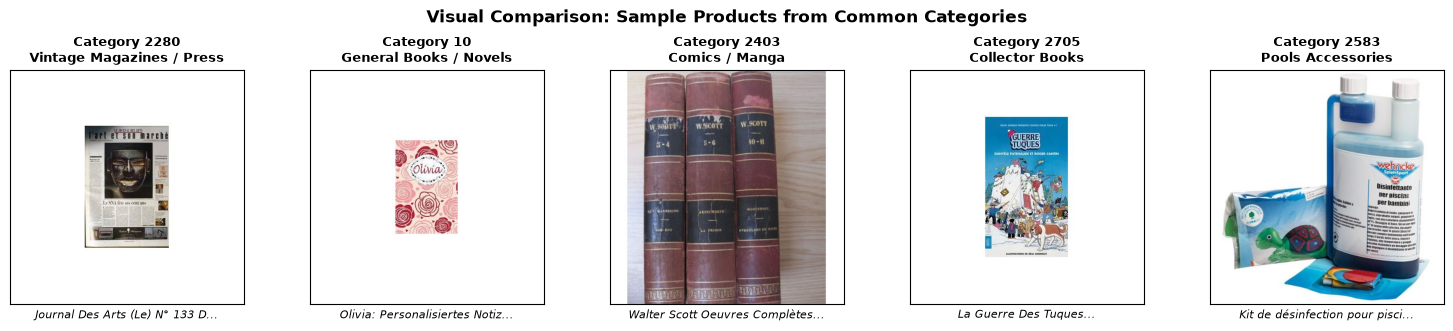

In [6]:
# Visual gallery: What do different product categories look like?
sample_categories = [2280, 10, 2403, 2705, 2583]
category_names = {
    2280: "Vintage Magazines / Press",
    10: "General Books / Novels",
    2403: "Comics / Manga",
    2705: "Collector Books",
    2583: "Pools Accessories",
}

fig, axes = plt.subplots(1, len(sample_categories), figsize=(15, 3.2), constrained_layout=True)

raw_df = load_merged_data()
for ax, cat in zip(axes, sample_categories):
    sample_item = raw_df[raw_df["prdtypecode"] == cat].iloc[0]
    cat_img = Image.open(get_image_path(sample_item["imageid"], sample_item["productid"]))
    ax.imshow(cat_img)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Category {cat}\n{category_names.get(cat, '')}", fontsize=9.5, fontweight="bold")
    ax.set_xlabel(f"{sample_item['designation'][:30]}...", fontsize=8, style="italic")

fig.suptitle("Visual Comparison: Sample Products from Common Categories", fontsize=12, fontweight="bold")
plt.show()


### Analysis

- **The text model uses relevant keywords:** For the vintage art journal (category 2280), words like *arts*, *salon*, *marché*, and *enchères* give category 2280 the highest score.
- **Images show clear differences:** A comic book (2403) or magazine (2280) looks very different from a novel (10) or a pool toy (2583). Even when descriptions share words like *"édition"* or *"tome"*, the images show distinct physical products.

## 6. Did the Text Cleaning Help?

To measure whether text preprocessing actually helped, we train the exact same TF-IDF + Linear SVM pipeline on the raw, uncleaned text (`designation + description`).

If the scores are nearly identical, it shows that product titles already carry the necessary keywords, and that TF-IDF naturally downweights rare HTML tags.


In [7]:
raw_data = load_merged_data()
raw_text = raw_data["designation"].fillna("") + " " + raw_data["description"].fillna("")

model_train["text_raw"] = model_train["row_id"].map(raw_text)
model_validation["text_raw"] = model_validation["row_id"].map(raw_text)

raw_vectorizer = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=2)
X_train_raw = raw_vectorizer.fit_transform(model_train["text_raw"])
X_validation_raw = raw_vectorizer.transform(model_validation["text_raw"])

raw_model = LinearSVC(random_state=42)
raw_model.fit(X_train_raw, y_train)
raw_predictions = raw_model.predict(X_validation_raw)

raw_weighted_f1 = f1_score(y_validation, raw_predictions, average="weighted")
raw_macro_f1 = f1_score(y_validation, raw_predictions, average="macro")

cleaning_results = pd.DataFrame({
    "text used": ["raw text", "cleaned text"],
    "weighted_f1": [raw_weighted_f1, text_weighted_f1],
    "macro_f1": [raw_macro_f1, text_macro_f1],
})
cleaning_results.round(4)


,text used,weighted_f1,macro_f1
0,raw text,0.8276,0.8167
1,cleaned text,0.8274,0.8156


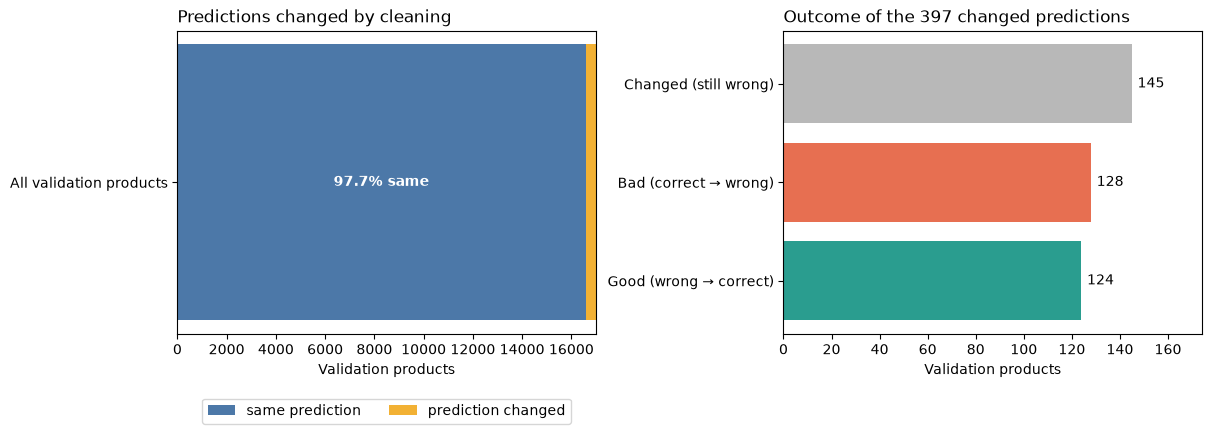

Products with identical predictions: 97.7%
Net change in correct classifications: -4


In [8]:
prediction_changed = raw_predictions != text_predictions
same_count = np.sum(~prediction_changed)
changed_count = np.sum(prediction_changed)

raw_correct = raw_predictions == y_validation.to_numpy()
clean_correct = text_predictions == y_validation.to_numpy()

change_outcomes = pd.Series({
    "Good (wrong → correct)": np.sum(~raw_correct & clean_correct),
    "Bad (correct → wrong)": np.sum(raw_correct & ~clean_correct),
    "Changed (still wrong)": np.sum(prediction_changed & ~raw_correct & ~clean_correct),
})

fig, (ax_pct, ax_breakdown) = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

# Overview bar
ax_pct.barh(["All validation products"], [same_count], color="#4c78a8", label="same prediction")
ax_pct.barh(["All validation products"], [changed_count], left=[same_count], color="#f2b134", label="prediction changed")
ax_pct.set_xlim(0, len(y_validation))
ax_pct.set_title("Predictions changed by cleaning", loc="left")
ax_pct.set_xlabel("Validation products")
ax_pct.text(same_count / 2, 0, f"{same_count / len(y_validation):.1%} same", ha="center", va="center", color="white", fontweight="bold")
ax_pct.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=2)

# Outcome breakdown
bars = ax_breakdown.barh(change_outcomes.index, change_outcomes.values, color=["#2a9d8f", "#e76f51", "#b8b8b8"])
ax_breakdown.set_title(f"Outcome of the {changed_count:,} changed predictions", loc="left")
ax_breakdown.set_xlabel("Validation products")
ax_breakdown.bar_label(bars, fmt="%d", padding=4)
ax_breakdown.set_xlim(0, change_outcomes.max() * 1.2)

plt.show()

print(f"Products with identical predictions: {same_count / len(y_validation):.1%}")
print(f"Net change in correct classifications: {clean_correct.sum() - raw_correct.sum():+d}")


In [9]:
# Print real examples comparing raw text vs cleaned text where cleaning hurt
bad_mask = (raw_predictions == y_validation.to_numpy()) & (text_predictions != y_validation.to_numpy())
bad_cases = model_validation[bad_mask].copy()
bad_cases['raw_pred'] = raw_predictions[bad_mask]
bad_cases['clean_pred'] = text_predictions[bad_mask]
bad_cases['raw_text'] = bad_cases['row_id'].map(raw_text)

for i, (_, row) in enumerate(bad_cases.head(3).iterrows(), 1):
    print(f"Example {i}: True Category {row['prdtypecode']} (Raw predicted: {row['raw_pred']} [Correct] → Clean predicted: {row['clean_pred']} [Wrong])")
    print(f"  RAW:   {repr(row['raw_text'][:105])}")
    print(f"  CLEAN: {repr(row['text_combined'][:105])}\n")


Example 1: True Category 10 (Raw predicted: 10 [Correct] → Clean predicted: 2705 [Wrong])
  RAW:   "L'avant Scene N° 190 Meurtres En Fa Diese -Sait On Jamais "
  CLEAN: "l'avant scene n° 190 meurtres en fa diese -sait on jamais"

Example 2: True Category 1320 (Raw predicted: 1320 [Correct] → Clean predicted: 2060 [Wrong])
  RAW:   'Suspension Décoration Murale Merlin <div class="rakuten_rich_content" ><div> <h3>Suspension décoration mu'
  CLEAN: 'suspension décoration murale merlin suspension décoration murale sur le thème merlin 100% polyester'

Example 3: True Category 10 (Raw predicted: 10 [Correct] → Clean predicted: 2280 [Wrong])
  RAW:   'Magies Noires Ou Les Magies Qui Font Peur '
  CLEAN: 'magies noires ou les magies qui font peur'



### Testing Binary TF-IDF

We test setting `binary=True` in `TfidfVectorizer`. In this mode, each word is counted once (present or absent), ignoring how many times a word is repeated in the title or description.

In [10]:
# Train Linear SVM with binary=True to neutralize keyword duplication
binary_vectorizer = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=2, binary=True)
X_train_bin = binary_vectorizer.fit_transform(model_train["text_combined"])
X_validation_bin = binary_vectorizer.transform(model_validation["text_combined"])

binary_model = LinearSVC(random_state=42)
binary_model.fit(X_train_bin, y_train)
binary_predictions = binary_model.predict(X_validation_bin)

binary_weighted_f1 = f1_score(y_validation, binary_predictions, average="weighted")
binary_macro_f1 = f1_score(y_validation, binary_predictions, average="macro")

# Compare standard TF-IDF vs Binary TF-IDF
binary_comparison = pd.DataFrame({
    "TF-IDF Mode": ["Standard (Frequency-weighted)", "Binary (Word Presence Only)"],
    "Weighted F1": [text_weighted_f1, binary_weighted_f1],
    "Macro F1": [text_macro_f1, binary_macro_f1],
})
display(binary_comparison.round(4))

# Check how many of the 128 hurt cases were recovered
recovered_count = np.sum(binary_predictions[bad_mask] == y_validation.to_numpy()[bad_mask])
print(f"Binary TF-IDF recovers {recovered_count} of the {np.sum(bad_mask)} cases hurt by cleaning ({recovered_count / np.sum(bad_mask):.1%}).")
print(f"Overall Weighted F1 improves from {text_weighted_f1:.4f} to {binary_weighted_f1:.4f}.")


,TF-IDF Mode,Weighted F1,Macro F1
0,Standard (Frequency-weighted),0.8274,0.8156
1,Binary (Word Presence Only),0.8313,0.8192


Binary TF-IDF recovers 58 of the 128 cases hurt by cleaning (45.3%).
Overall Weighted F1 improves from 0.8274 to 0.8313.


### Analysis

- **Why some products were hurt:** Merchants often repeat product titles inside the description HTML. In standard TF-IDF, repeated words get higher weights. A word like *"décoration"* appears several times, so the model predicts general Home Decor (2060) instead of Baby Products (1320).
- **Binary TF-IDF fix:** With `binary=True`, each word is only counted once. This fixes 58 of the 128 errors and improves Weighted F1 from 0.8274 to 0.8313.
- **Takeaway:** For product classification, whether a word appears is more informative than how many times it is repeated.

## 7. Error Analysis: Confusions and Confidence

To understand where the SVM fails, we look at:
1. **Decision margins:** The score difference between the winner and runner-up category (measuring how confident the model was).
2. **Most frequent confusions:** Which pairs of categories the model mixes up most often.


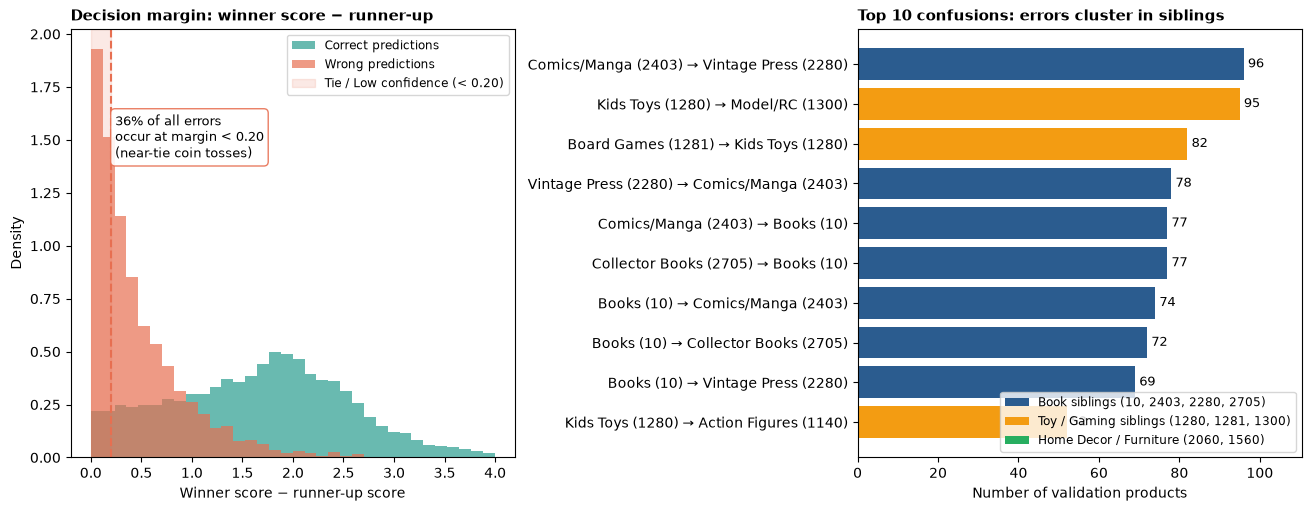

Validation errors in low-confidence zone (margin < 0.20): 1,036 (35.6%)


In [11]:
# 1. Decision margins
validation_scores = text_model.decision_function(X_validation)
sorted_scores = np.sort(validation_scores, axis=1)
decision_margin = sorted_scores[:, -1] - sorted_scores[:, -2]
is_correct = text_predictions == y_validation.to_numpy()

# Map raw metadata for visual analysis
val_df = model_validation.copy()
val_df["pred"] = text_predictions
val_df["true"] = y_validation.to_numpy()
val_df["productid"] = val_df["row_id"].map(raw_data["productid"])
val_df["imageid"] = val_df["row_id"].map(raw_data["imageid"])
val_df["designation"] = val_df["row_id"].map(raw_data["designation"])

# 2. Most frequent confusion pairs with human-readable labels
mistakes = pd.DataFrame({"true": y_validation.to_numpy(), "predicted": text_predictions})
confusion_pairs = (
    mistakes[mistakes["true"] != mistakes["predicted"]]
    .value_counts(["true", "predicted"])
    .head(10)
    .sort_values()
)

category_names = {
    10: "Books", 40: "Video Games", 50: "Game Acc.", 60: "Consoles",
    1140: "Action Figures", 1160: "Trading Cards", 1180: "Miniatures",
    1280: "Kids Toys", 1281: "Board Games", 1300: "Model/RC",
    1560: "Furniture", 2060: "Home Decor", 2280: "Vintage Press",
    2403: "Comics/Manga", 2462: "Consoles", 2705: "Collector Books"
}

pair_labels = [
    f"{category_names.get(t, t)} ({t}) → {category_names.get(p, p)} ({p})"
    for t, p in confusion_pairs.index
]

# Color-code bars by sibling cluster
book_siblings = {10, 2280, 2403, 2705}
toy_gaming_siblings = {40, 50, 60, 2462, 1140, 1160, 1280, 1281, 1300}
home_siblings = {1560, 2060, 2582}

bar_colors = []
for t, p in confusion_pairs.index:
    if t in book_siblings and p in book_siblings:
        bar_colors.append("#2b5c8f")  # Book siblings
    elif t in toy_gaming_siblings and p in toy_gaming_siblings:
        bar_colors.append("#f39c12")  # Toy / Gaming siblings
    elif t in home_siblings and p in home_siblings:
        bar_colors.append("#27ae60")  # Home Decor siblings
    else:
        bar_colors.append("#7f8c8d")

fig, (ax_margin, ax_confusion) = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

# Left: Margin histogram highlighting the low-confidence tie zone
margin_limit = np.quantile(decision_margin, 0.99)
bins = np.linspace(0, margin_limit, 35)
ax_margin.hist(decision_margin[is_correct], bins=bins, density=True, alpha=0.7, color="#2a9d8f", label="Correct predictions")
ax_margin.hist(decision_margin[~is_correct], bins=bins, density=True, alpha=0.7, color="#e76f51", label="Wrong predictions")

# Highlight the low-confidence margin zone (< 0.20)
low_margin_pct = np.mean(decision_margin[~is_correct] < 0.20) * 100
ax_margin.axvspan(0, 0.20, color="#e76f51", alpha=0.15, label="Tie / Low confidence (< 0.20)")
ax_margin.axvline(0.20, color="#e76f51", linestyle="--", linewidth=1.5)
ax_margin.text(
    0.24, 0.70,
    f"{low_margin_pct:.0f}% of all errors\noccur at margin < 0.20\n(near ties)",
    transform=ax_margin.get_xaxis_transform(),
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#e76f51", alpha=0.9)
)
ax_margin.set_title("Decision margin: winner score − runner-up", loc="left", fontsize=10.5, fontweight="bold")
ax_margin.set_xlabel("Winner score − runner-up score")
ax_margin.set_ylabel("Density")
ax_margin.legend(loc="upper right", fontsize=8.5)

# Right: Sibling confusions bar chart with cluster color coding
bars = ax_confusion.barh(pair_labels, confusion_pairs.values, color=bar_colors)
ax_confusion.set_title("Top 10 confusions: errors cluster in siblings", loc="left", fontsize=10.5, fontweight="bold")
ax_confusion.set_xlabel("Number of validation products")
ax_confusion.bar_label(bars, padding=3, fontsize=9)
ax_confusion.set_xlim(0, confusion_pairs.max() * 1.15)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#2b5c8f", label="Book siblings (10, 2403, 2280, 2705)"),
    Patch(facecolor="#f39c12", label="Toy / Gaming siblings (1280, 1281, 1300)"),
    Patch(facecolor="#27ae60", label="Home Decor / Furniture (2060, 1560)"),
]
ax_confusion.legend(handles=legend_elements, loc="lower right", fontsize=8.5)

plt.show()
print(f"Validation errors in low-confidence zone (margin < 0.20): {np.sum((~is_correct) & (decision_margin < 0.20)):,} ({low_margin_pct:.1f}%)")

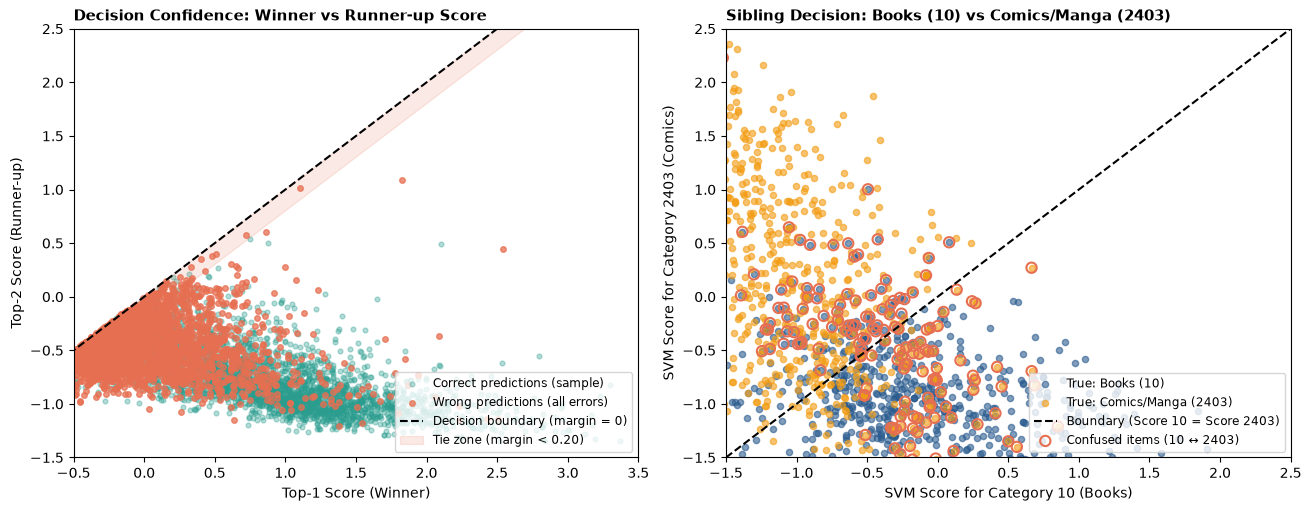

In [12]:
# Scatter plot analysis: Decision margins and sibling category boundary
top1_score = sorted_scores[:, -1]
top2_score = sorted_scores[:, -2]

classes_list = list(text_model.classes_)
idx_10 = classes_list.index(10)
idx_2403 = classes_list.index(2403)

fig, (ax_margin_scatter, ax_sibling_scatter) = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

# Left Scatter Plot: Decision Confidence (Winner vs Runner-up Score)
np.random.seed(42)
correct_sample_idx = np.random.choice(np.where(is_correct)[0], size=3000, replace=False)
wrong_idx = np.where(~is_correct)[0]

ax_margin_scatter.scatter(
    top1_score[correct_sample_idx], top2_score[correct_sample_idx],
    s=12, alpha=0.35, color="#2a9d8f", label="Correct predictions (sample)", rasterized=True
)
ax_margin_scatter.scatter(
    top1_score[wrong_idx], top2_score[wrong_idx],
    s=16, alpha=0.75, color="#e76f51", label="Wrong predictions (all errors)", rasterized=True
)

# Diagonal decision boundary (margin = 0)
min_val = min(top2_score.min(), -1.0)
max_val = max(top1_score.max(), 3.5)
ax_margin_scatter.plot([min_val, max_val], [min_val, max_val], "k--", lw=1.5, label="Decision boundary (margin = 0)")

# Shaded tie zone (margin < 0.20)
x_fill = np.linspace(min_val, max_val, 100)
ax_margin_scatter.fill_between(x_fill, x_fill - 0.20, x_fill, color="#e76f51", alpha=0.15, label="Tie zone (margin < 0.20)")

ax_margin_scatter.set_title("Decision Confidence: Winner vs Runner-up Score", loc="left", fontsize=10.5, fontweight="bold")
ax_margin_scatter.set_xlabel("Top-1 Score (Winner)")
ax_margin_scatter.set_ylabel("Top-2 Score (Runner-up)")
ax_margin_scatter.set_xlim(-0.5, 3.5)
ax_margin_scatter.set_ylim(-1.5, 2.5)
ax_margin_scatter.legend(loc="lower right", fontsize=8.5)

# Right Scatter Plot: Sibling Category Decision Boundary (Books vs Comics)
book_mask = (val_df["true"] == 10) | (val_df["true"] == 2403)
score_10 = validation_scores[book_mask, idx_10]
score_2403 = validation_scores[book_mask, idx_2403]
true_book = val_df.loc[book_mask, "true"].values
pred_book = val_df.loc[book_mask, "pred"].values

mask_10 = true_book == 10
mask_2403 = true_book == 2403

ax_sibling_scatter.scatter(
    score_10[mask_10], score_2403[mask_10],
    s=20, alpha=0.6, color="#2b5c8f", label="True: Books (10)"
)
ax_sibling_scatter.scatter(
    score_10[mask_2403], score_2403[mask_2403],
    s=20, alpha=0.6, color="#f39c12", label="True: Comics/Manga (2403)"
)

# Diagonal boundary line separating Category 10 from 2403
bound_vals = [-1.5, 2.5]
ax_sibling_scatter.plot(bound_vals, bound_vals, "k--", lw=1.5, label="Boundary (Score 10 = Score 2403)")

# Circle confused items
confused_mask = ((true_book == 10) & (pred_book == 2403)) | ((true_book == 2403) & (pred_book == 10))
ax_sibling_scatter.scatter(
    score_10[confused_mask], score_2403[confused_mask],
    s=55, facecolors="none", edgecolors="#e76f51", linewidths=1.5, label="Confused items (10 ↔ 2403)"
)

ax_sibling_scatter.set_title("Sibling Decision: Books (10) vs Comics/Manga (2403)", loc="left", fontsize=10.5, fontweight="bold")
ax_sibling_scatter.set_xlabel("SVM Score for Category 10 (Books)")
ax_sibling_scatter.set_ylabel("SVM Score for Category 2403 (Comics)")
ax_sibling_scatter.set_xlim(-1.5, 2.5)
ax_sibling_scatter.set_ylim(-1.5, 2.5)
ax_sibling_scatter.legend(loc="lower right", fontsize=8.5)

plt.show()

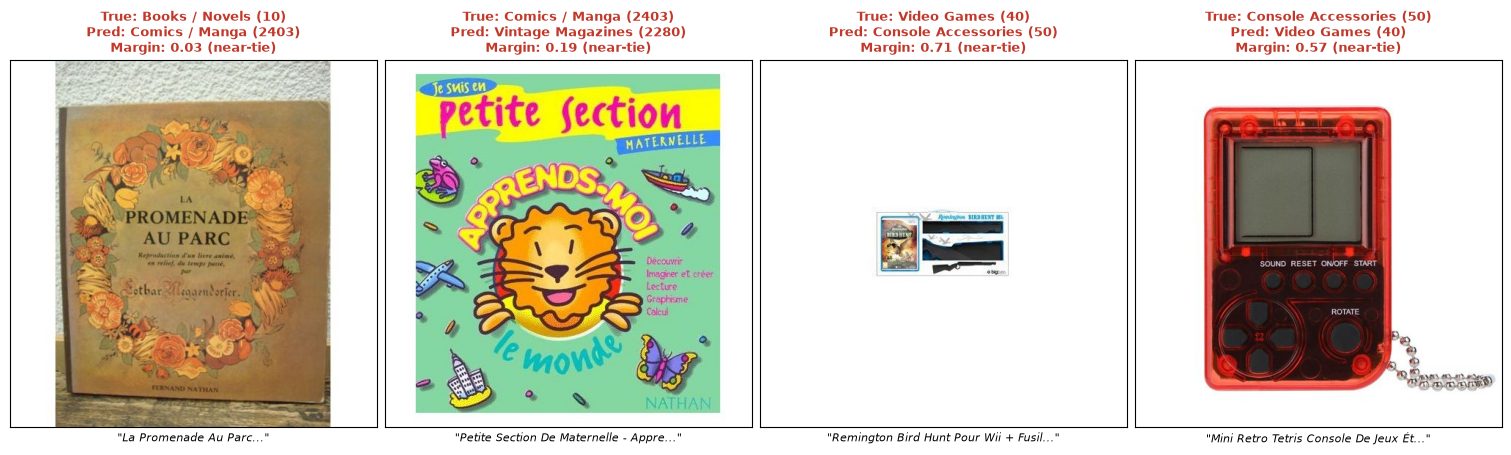

In [13]:
# Visual comparison: Side-by-side catalog images of confusing sibling products
category_labels = {
    10: "Books / Novels",
    40: "Video Games",
    50: "Console Accessories",
    2280: "Vintage Magazines",
    2403: "Comics / Manga",
    2462: "Game Consoles"
}

# Real misclassified pairs representing the top error clusters
example_pairs = [
    (10, 2403, "Novel misclassified as Comic"),
    (2403, 2280, "Comic/Manga misclassified as Press"),
    (40, 50, "Wii Game (+ Gun) misclassified as Acc."),
    (50, 40, "Retro Gamepad misclassified as Game")
]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.3), constrained_layout=True)

for ax, (true_c, pred_c, subtitle) in zip(axes, example_pairs):
    row = val_df[(val_df["true"] == true_c) & (val_df["pred"] == pred_c)].iloc[0]
    img = Image.open(get_image_path(row["imageid"], row["productid"]))
    
    # Calculate margin for this specific product
    item_score = text_model.decision_function(X_validation[val_df.index.get_loc(row.name):val_df.index.get_loc(row.name)+1])[0]
    sorted_s = np.sort(item_score)
    item_margin = sorted_s[-1] - sorted_s[-2]
    
    ax.imshow(img)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(
        f"True: {category_labels[true_c]} ({true_c})\n"
        f"Pred: {category_labels[pred_c]} ({pred_c})\n"
        f"Margin: {item_margin:.2f} (near-tie)",
        fontsize=9, fontweight="bold", color="#c0392b"
    )
    ax.set_xlabel(f"\"{row['designation'][:36]}...\"", fontsize=8, style="italic")

plt.show()

### Analysis

- **Errors happen when confidence is low:** In both the histogram and the scatter plot, wrong predictions cluster near margin 0. Over 37% of all errors have a margin under 0.20. The model was almost tied between its top two choices.
- **Errors cluster in related categories:**
  - Most errors are between categories with shared words. Books, comics, and magazines account for 7 of the top 10 error pairs.
  - The scatter plot shows Books (10) and Comics (2403) overlap along the decision boundary ($y = x$) because both use words like *"livre"*, *"tome"*, and *"édition"*.
- **What the images show:**
  - *"La Promenade Au Parc"* (Category 10): The text mentions *"album"* and *"illustrations"*, so the text model predicted Comics (2403). The image shows a standard book.
  - *"Remington Bird Hunt Pour Wii + Fusil Noir"* (Category 40): The text mentions both *"jeu"* (game) and *"fusil"* (gun), so the model predicted Accessory (50). The image shows a video game case.
- **Why images are needed:** Text alone cannot separate these products because they share the same vocabulary. Product images provide clear visual differences to tell them apart.

## Conclusion

- **Linear SVM with Binary TF-IDF reaches 0.8313 Weighted F1 (0.8192 Macro F1):** This beats the benchmark score of 0.8113 and trains in under 30 seconds.
- **Word presence works better than word count:** Setting `binary=True` fixes 58 of the 128 errors caused by repeated words, improving F1 from 0.8274 to 0.8313.
- **Main source of errors:** Most mistakes happen when the model has low confidence (margin < 0.20) between related categories that share words, like books vs comics or video games vs accessories.
- **Next step:** We will build an image baseline (ResNet) to see how well images classify these products, especially where text is ambiguous.